# NOTES ON 2D Diffusion class

## Mathematical steps
 - Initially we have the transport equation
 - we neglect convection and source terms
 - we get: $\frac {\partial \underline{u}}{\partial t} - \nabla \cdot (\Gamma \nabla \underline{u}) = 0$
 - then we apply $\Gamma = \nu \text{  constant}$
 - and we have (for a 2D case):
        $$\frac {\partial u}{\partial t} - \nu \frac{\partial^2 u}{\partial x^2} - \nu \frac{\partial^2 u}{\partial y^2}$$
        $$\frac {\partial v}{\partial t} - \nu \frac{\partial^2 v}{\partial x^2} - \nu \frac{\partial^2 v}{\partial y^2}$$

Here we have to discretize second order term, for that we use centered difference scheme:
to find that remender we can write the Taylor's expansion of $u(x + \Delta x)$ and $u(x - \Delta x)$ and sum them together to get $\frac {\partial ^2 u}{\partial x ^2} = \frac{u_{i+1} - 2u_i + u_{i-1}}{\Delta x ^2}$

we can write the discretized equations:
$$\frac{u^{n+1}_{i, j} - u^{n}_{i, j}}{\Delta t} - \nu (\frac{u^{n}_{i+1, j} - 2 u^{n}_{i, j} + u^{n}_{i-1, j}}{\Delta x ^2}) - \nu (\frac{u^{n}_{i, j+1} - 2 u^{n}_{i, j} + u^{n}_{i, j-1}}{\Delta y ^2})$$

we than isolate the term of the next time step:
$$u^{n+1}_{i, j} = u^n_{i,j} + \frac{\nu \Delta t}{\Delta x ^2} (u^{n}_{i+1, j} - 2 u^{n}_{i, j} + u^{n}_{i-1, j}) + \frac{\nu \Delta t}{\Delta x ^2} (u^{n}_{i, j+1} - 2 u^{n}_{i, j} + u^{n}_{i, j-1})$$

and:
$$v^{n+1}_{i, j} = v^n_{i,j} + \frac{\nu \Delta t}{\Delta x ^2} (v^{n}_{i+1, j} - 2 v^{n}_{i, j} + v^{n}_{i-1, j}) + \frac{\nu \Delta t}{\Delta x ^2} (v^{n}_{i, j+1} - 2 v^{n}_{i, j} + v^{n}_{i, j-1})$$

Now we can procede to the code

In [ ]:
import numpy as np
from matplotlib import pyplot as plt, cm
from matplotlib import animation

In [36]:
#set initial parameters:

nx = 51
ny = 51
domain = [(0, 2),(0, 2)]
dx = (domain[0][1] - domain[0][0]) / (nx - 1)
dy = (domain[1][1] - domain[1][0]) / (ny - 1)

sigma = 0.1
dt = sigma * dx * dy
time = 0.5 #in seconds
timesteps = int(time / dt)

In [37]:
#initialize mesh 
x = np.linspace(domain[0][0], domain[0][1], nx)
y = np.linspace(domain[1][0], domain[1][1], ny)
X, Y = np.meshgrid(x, y)

In [38]:
#initialize the field
u = np.ones((ny, nx))

The initial conditions are:
u = 2 entre 0.5 e 1 de x e y

In [39]:
#initialize boundary conditions

u[int(0.5/dx):int(1/dx+1), int(0.5/dy):int(1/dy+1)] = 2

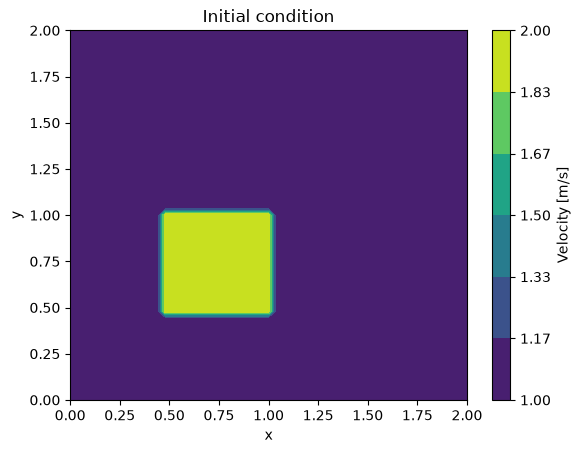

In [40]:
#plot the boundary conditionts
fig, ax = plt.subplots()
levels = np.linspace(u.min(), u.max(), 7)
contour = ax.contourf(X, Y, u, levels = levels)
fig.colorbar(contour, ax=ax, label="Velocity [m/s]", format="%.2f")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Initial condition")
fig.savefig("initial_condition.png", dpi=300, bbox_inches="tight")
plt.show()

In [49]:
#loop for solution diffusion
nu = 0.05 #diffusion coefficient

solution = [u.copy()]

for n in range(timesteps):
    un = u.copy()
    u[1:-1, 1:-1] = (un[1:-1, 1:-1] + 
                    nu * dt / dx**2 * (un[2:, 1:-1] - 2 * un[1:-1, 1:-1] + un[:-2, 1:-1]) + 
                    nu * dt / dy**2 * (un[1:-1, 2:] - 2 * un[1:-1, 1:-1] + un[1:-1, :-2]) )
    
    #boundary conditions
    u[0, :] = 1
    u[-1, :] = 1
    u[:, 0] = 1
    u[:, -1] = 1
    solution.append(u.copy())



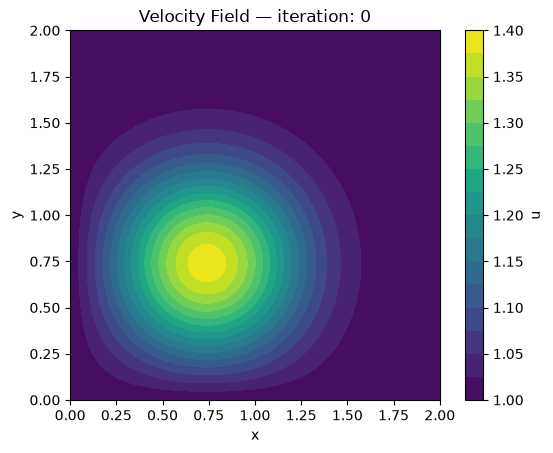

In [50]:
fig, ax = plt.subplots()

contour = ax.contourf(X, Y, u, levels=15, cmap="viridis")
fig.colorbar(contour, ax=ax, label="u")

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Velocity Field — iteration: 0")
ax.set_aspect("equal")

fig.savefig("velocity_field_last_iteration.png", dpi=300, bbox_inches="tight")
plt.show()

In [57]:
fig, ax = plt.subplots()

vmin = min(s.min() for s in solution)
vmax = max(s.max() for s in solution)


mesh = ax.pcolormesh(X, Y, solution[0], cmap="viridis", vmin=vmin, vmax=vmax, shading="auto")
fig.colorbar(mesh, ax=ax, label="u")
title = ax.set_title("Velocity Field — iteration: 0")
ax.set_aspect("equal")

def update(frame_index):
    mesh.set_array(solution[frame_index].ravel())
    title.set_text(f"Velocity Field — iteration: {frame_index}")
    return mesh, title

anim = animation.FuncAnimation(fig, update, frames=range(0, len(solution), 10), blit=True)
anim.save("diffusion.gif", writer=animation.PillowWriter(fps=10))
plt.close(fig)

# IMPLICIT SOLVERS

Explicit solvers calculate the next time-step based on the current state of the system (they are easy to implement but require very small timesteps)

Implicitr solvers calculate the next time=step based on both the new and old timestep, implicit solvers require solution of systems of equations but can be more stable
we will discuss more about implicit solvers in step 17